# Update the UIRJ results

**Private working copy. Nothing here uploads, sends messages, scores proteins or runs a model.**

Use this notebook when someone sends new sequences or result files. It checks what arrived, shows what can be summarized, and saves a new folder without replacing the old one.

The included example uses actual repository files, not invented data. Sanithu's source is pinned to `bc3a1070` (Oct25 Jacob upload). **This is not the latest Jacob Drive delivery.** Some files disagree; the notebook should show you that, not hide it.

**Reading route:** choose files → inspect sequences → check disagreements → review saved scores → export. Run all cells in order; read each table before putting anything into the paper.

## 1. Which files do you want to use?

For the first run, leave these settings alone. The real examples are included beside this notebook.

For an update, copy `inputs.json` to `my_inputs.json`, change its paths and cohort names, and select it below. A **cohort** means one named collection from one run, not just a method name. Keep Jacob's collection separate from Sanithu's unless the team establishes that they are the same. See `GUIDE.md` for the exact file formats.

`PROJECT_FOLDER` is the folder containing this notebook, **not** a source repository. In VS Code/Jupyter, open this folder before running. If needed, replace `Path.cwd()` with its path. Exports always go to a new dated subfolder.

In [1]:
from pathlib import Path
import json
PROJECT_FOLDER = Path.cwd()
CONFIG_FILE = PROJECT_FOLDER / "inputs.json"   # change to "my_inputs.json" for your update
EXPORT_FOLDER = PROJECT_FOLDER / "exports"
config = json.loads(CONFIG_FILE.read_text())
print(config["title"])

Private repository snapshot review — not latest Jacob Drive


### Does the selection look right?

Each row below is an actual file the notebook will read. `value_column` names the measurement; `domain_column` says whether values refer to separate antibody domains or loops. A missing file will be listed, not replaced by an older result. The workbook example and the ensemble CSV are two views of the same export: they are shown separately, never added together.

In [2]:
import sys
sys.path.insert(0, str(PROJECT_FOLDER))
import pandas as pd
from IPython.display import display, Markdown, Image
import update_results as update
selection = [dict(type=kind, **item) for kind in ("fasta", "designs", "metrics") for item in config[kind]]
for item in selection:
    display(Markdown(f'**{item["type"]}** · `{item["path"]}` — {item["cohort"]}  \nValue: `{item.get("value_column", "sequence")}`; domain: `{item.get("domain_column") or "not specified"}`'))

**fasta** · `inputs/sanithu/baseline_sequences/baseline_sequences_final_filled/9NH7_EBH.fa` — repository-final-filled  
Value: `sequence`; domain: `not specified`

**fasta** · `inputs/sanithu/ensemble_sequences/ensemble_sequences_final_filled/9NH7.fa` — repository-final-filled  
Value: `sequence`; domain: `not specified`

**fasta** · `inputs/sanithu/AbMPNN_sequences/9NH7_AbMPNN_100_FINAL_FILLED.fa` — repository-final-filled  
Value: `sequence`; domain: `not specified`

**fasta** · `inputs/sanithu/baseline_sequences/baseline_sequences_final_filled/9NFU.fa` — repository-final-filled  
Value: `sequence`; domain: `not specified`

**fasta** · `inputs/sanithu/ensemble_sequences/ensemble_sequences_final_filled/9NFU.fa` — repository-final-filled  
Value: `sequence`; domain: `not specified`

**fasta** · `inputs/sanithu/AbMPNN_sequences/9NFU_AbMPNN_100_FINAL_FILLED.fa` — repository-final-filled  
Value: `sequence`; domain: `not specified`

... (4 outputs left out)

**metrics** · `inputs/sanithu/RSMD_RESULTS/cdr_rmsd_framework.csv` — repository-final-filled  
Value: `framework_rmsd_angstrom`; domain: `domain`

**metrics** · `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv` — Jacob-repository-Oct25  
Value: `rmsd_angstrom`; domain: `cdr`

**metrics** · `inputs/sanithu/wilcoxon_task_files/3_data/oasis_scores_promb.csv` — Jacob-repository-Oct25  
Value: `oasis_identity`; domain: `cdr`

**metrics** · `inputs/sanithu/Oasis_compute/output/oasis_output_ensemble/9NH7_ensemble_oasis.xlsx` — repository-final-filled  
Value: `OASis Identity`; domain: `not specified`

## 2. What sequences arrived?

A FASTA header contains the actual sample or seed ID. These are retained: baseline sample 1 is **not** renamed to 0. Duplicate IDs, unresolved `X` residues and malformed records stop the run with a specific message. Repeated *sequences* are retained as repeated draws and counted below.

The sequence fingerprint is only a compact way to compare exact text. It does not prove that a model actually used that sequence.

In [3]:
run = update.load_run(PROJECT_FOLDER, config)
seq = pd.DataFrame(run["sequences"])
inventory = seq.groupby(["cohort", "structure", "method"]).agg(draws=("record_id", "size"), unique_sequences=("sequence_sha256", "nunique"))
display(inventory)
print("Full sequences are retained in the export; the table counts exact unique text.")

draws  unique_sequences
cohort                  structure method                           
Jacob-repository-Oct25  9NFU      baseline    100               100
                                  ensemble    100               100
                        9NH7      baseline    100                96
                                  ensemble    100               100
repository-final-filled 9NFU      AbMPNN      100               100
                                  baseline    100               100
                                  ensemble    100               100
                        9NH7      AbMPNN      100                99
                                  baseline    100                94
                                  ensemble    100                76

Full sequences are retained in the export; the table counts exact unique text.


## 3. Are the two collections really the same?

This compares exact sequences with the same case, method and sample/seed number across cohorts. **It does not merge them or pair methods.** A mismatch means that a score from one collection cannot be attached to the other merely because its row number looks familiar.

For the supplied files, the baseline disagreements are real. Ask for the precise sequence set that was scored and folded, or regenerate the affected measurements outside this notebook after the team chooses the intended set. All record-level details are exported.

In [4]:
comparison = pd.DataFrame(run["sequence_comparison"])
if comparison.empty:
    print("Only one cohort selected; no cross-cohort sequence comparison is possible.")
else:
    display(comparison.groupby(["structure", "method", "status"]).size().rename("records").to_frame())
    print("Exact IDs and sequence fingerprints are retained in sequence_comparison.csv.")

records
structure method   status                    
9NFU      AbMPNN   MISSING_LEFT           100
          baseline SEQUENCE_MISMATCH      100
          ensemble SEQUENCE_MISMATCH      100
9NH7      AbMPNN   MISSING_LEFT           100
          baseline SEQUENCE_MISMATCH      100
          ensemble SEQUENCE_MISMATCH      100

Exact IDs and sequence fingerprints are retained in sequence_comparison.csv.


### Do the measurement IDs cover the sequences?

Look for missing IDs and possible index shifts. For older structural files, baseline and AbMPNN IDs can start at 0 while their OASis IDs start at 1. The newer Jacob v3 file has its own naming convention. **No offset is applied automatically.** A full match of IDs still does not establish sequence or PDB provenance.

The compact table counts source/domain groups and flags. The full exported coverage table retains `sequence_ids_without_metric` (absent measurements) and `metric_ids_without_sequence` (measurements without a selected sequence). Empty values are counted explicitly; counts across sources are not independent observations.

In [5]:
coverage = pd.DataFrame(run["coverage"])
display(coverage.groupby(["cohort", "structure", "method"]).agg(groups=("domain", "size"), possible_offsets=("possible_index_offset", "sum"), missing_values=("n_missing_values", "sum")))
print("Per-source IDs and unmatched lists are retained in coverage.csv; no shifts are applied.")

groups  possible_offsets  \
cohort                  structure method                               
Jacob-repository-Oct25  9NFU      baseline       8                 0   
                                  ensemble       8                 0   
                        9NH7      baseline       4                 0   
                                  ensemble       4                 0   
repository-final-filled 9NFU      AbMPNN         3                 2   
                                  baseline       3                 2   
                                  ensemble       3                 0   
                        9NH7      AbMPNN         2                 1   
                                  baseline       2                 1   
                                  ensemble       3                 0   

                                            missing_values  
cohort                  structure method                    
Jacob-repository-Oct25  9NFU      baseline               0  
                                  ensemble               0  
                        9NH7      baseline               0  
                                  ensemble               0  
repository-final-filled 9NFU      AbMPNN                 0  
                                  baseline               0  
                                  ensemble               0  
                        9NH7      AbMPNN                 0  
                                  baseline               0  
                                  ensemble               0

Per-source IDs and unmatched lists are retained in coverage.csv; no shifts are applied.


## 4. What can we say from the saved values?

The following are **descriptive summaries of the files as supplied**, not certified measurements of the selected FASTAs. The score exports do not carry measured-sequence hashes, so they remain marked `UNBOUND_SOURCE_EXPORT`.

Cases (9NH7/9NFU), cohorts, domains, endpoints and source files stay separate. BioPhi Overview Identity, a loosely named `oasis_score`, percentile, and Jacob's `promb` peptide-content output are not silently substituted for one another. Means describe saved draws, not independent biological replicates.

There are no paired tests, p-values, confidence intervals, causal claims, or OASis–RMSD joins. Those need the correct inputs and an agreed statistical design. OASis is not clinical immunogenicity; predicted RMSD is not binding affinity.

In [6]:
summary = pd.DataFrame(run["summaries"])
for (cohort, case, endpoint, source), table in summary.groupby(["cohort", "structure", "endpoint", "source"]):
    display(Markdown(f"**{case} · {cohort}** — {endpoint}; source: `{Path(source).name}`"))
    display(table[["method", "domain", "n_present", "n_missing", "median"]].round(4).reset_index(drop=True))

**9NFU · Jacob-repository-Oct25** — CDR RMSD v3 export; source: `cdr_rmsd_results_v3.csv`

,method,domain,n_present,n_missing,median
0,baseline,H1,100,0,1.4185
1,baseline,H2,100,0,1.5015
2,baseline,H3,100,0,2.3775
3,baseline,L1,100,0,1.4635
4,baseline,L2,100,0,1.9570
5,baseline,L3,100,0,1.1560
6,ensemble,H1,100,0,1.5895
7,ensemble,H2,100,0,1.4645
8,ensemble,H3,100,0,4.4190
9,ensemble,L1,100,0,1.3365


**9NFU · Jacob-repository-Oct25** — promb human-oas peptide content (not BioPhi); source: `oasis_scores_promb.csv`

,method,domain,n_present,n_missing,median
0,baseline,VH,100,0,0.7143
1,baseline,VL,100,0,0.6250
2,ensemble,VH,100,0,0.6964
3,ensemble,VL,100,0,0.6354


**9NH7 · Jacob-repository-Oct25** — CDR RMSD v3 export; source: `cdr_rmsd_results_v3.csv`

,method,domain,n_present,n_missing,median
0,baseline,H1,100,0,3.575
1,baseline,H2,100,0,1.384
2,baseline,H3,100,0,1.610
3,ensemble,H1,100,0,4.877
4,ensemble,H2,100,0,2.918
5,ensemble,H3,100,0,8.142


... (16 outputs left out)

**9NH7 · repository-final-filled** — BioPhi source-selected OASis score; source: `oasis_proteinmpnn_summary.csv`

,method,domain,n_present,n_missing,median
0,baseline,not-specified-in-export,100,0,0.5981


**9NH7 · repository-final-filled** — Framework RMSD export; source: `cdr_rmsd_framework.csv`

,method,domain,n_present,n_missing,median
0,AbMPNN,VHH,100,0,1.408
1,baseline,VHH,100,0,1.453
2,ensemble,VHH,100,0,1.433


## 5. OASis: where do the saved scores fall?

Read each source separately: **source-selected score** is not automatically Overview Identity. The ensemble workbook repeats one CSV population and is a separate view, not another 100 independent observations. promb peptide content is a different endpoint. Fractions use a common 0–1 scale.

Each curve shows the fraction of saved values at or below the horizontal score. A curve farther right has larger saved scores, not demonstrated lower clinical immunogenicity. Method overlays are unpaired descriptive comparisons only. Every selected case/domain/source appears below; no hidden first-two limit.

### 9NFU / not-specified-in-export — BioPhi source-selected OASis score

Cohort: **repository-final-filled**. Source: `inputs/sanithu/Oasis_compute/output/oasis_abmpnn_summary.csv`. Unpaired saved-value distribution.

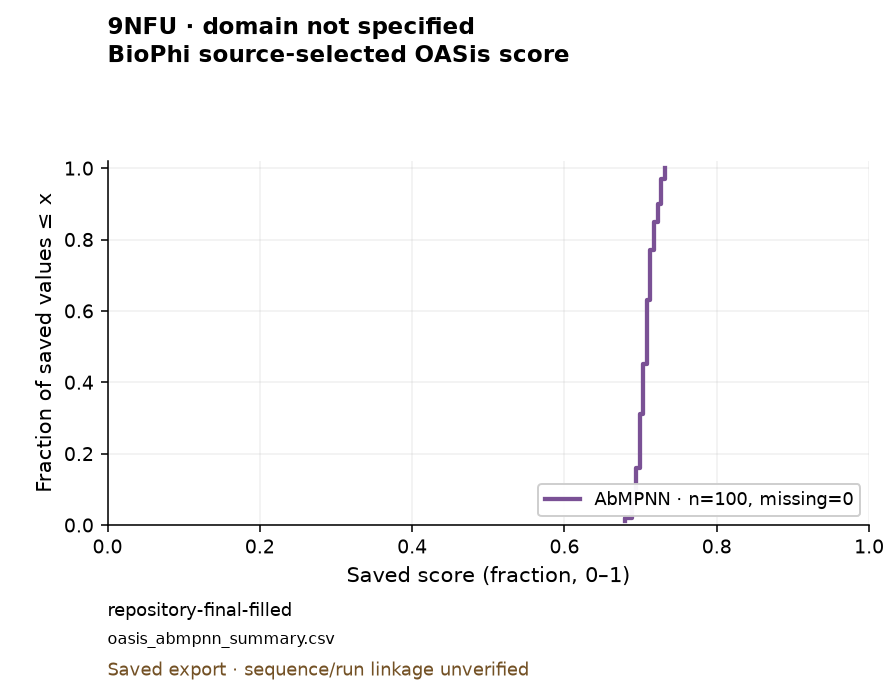

### 9NH7 / not-specified-in-export — BioPhi source-selected OASis score

Cohort: **repository-final-filled**. Source: `inputs/sanithu/Oasis_compute/output/oasis_abmpnn_summary.csv`. Unpaired saved-value distribution.

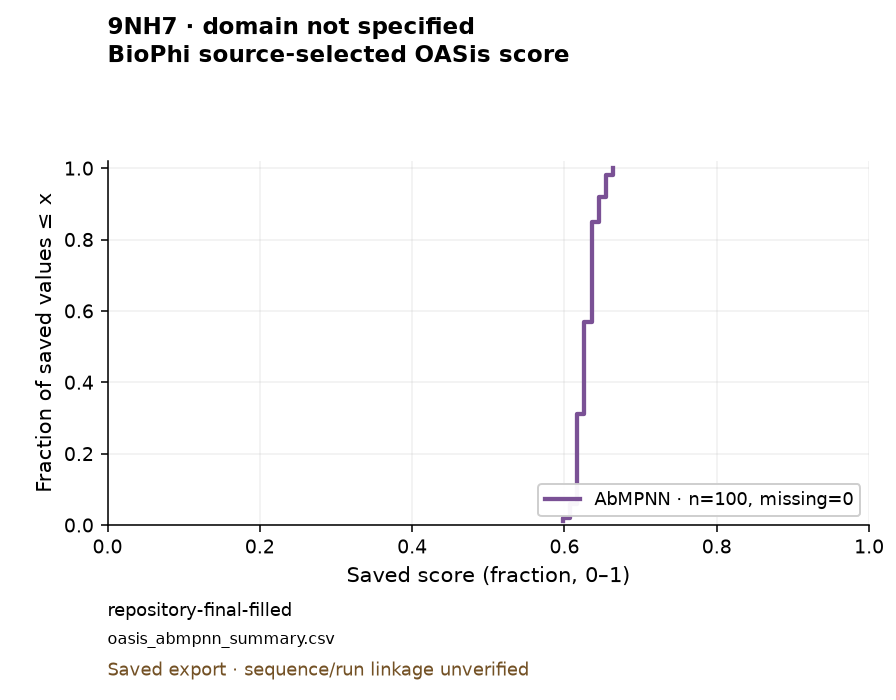

### 9NFU / not-specified-in-export — BioPhi Overview OASis Identity

Cohort: **repository-final-filled**. Source: `inputs/sanithu/Oasis_compute/output/oasis_ensemble_summary.csv`. Unpaired saved-value distribution.

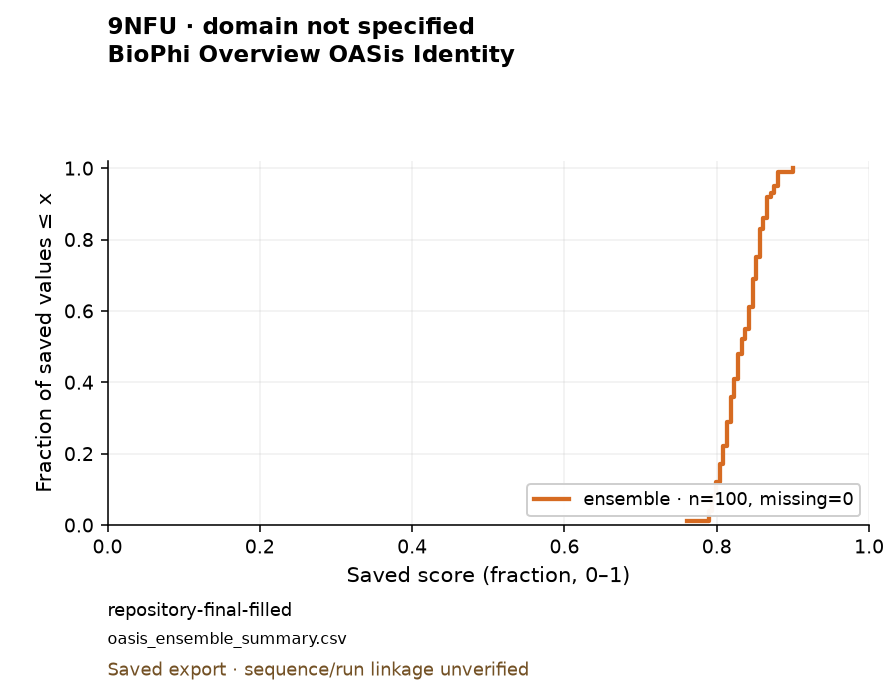

### 9NH7 / not-specified-in-export — BioPhi Overview OASis Identity

Cohort: **repository-final-filled**. Source: `inputs/sanithu/Oasis_compute/output/oasis_ensemble_summary.csv`. Unpaired saved-value distribution.

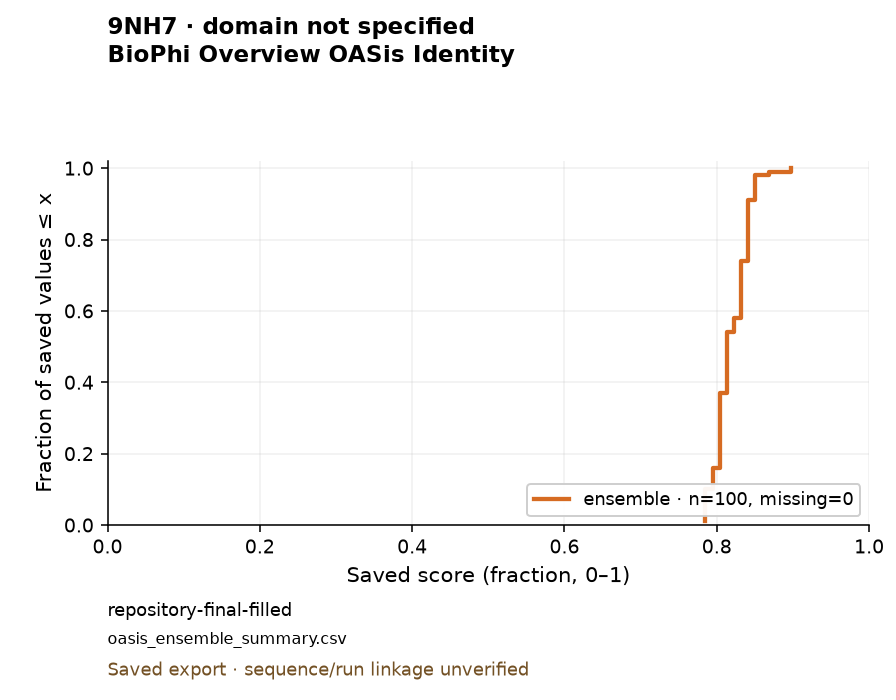

### 9NH7 / not-specified-in-export — BioPhi Overview OASis Identity

Cohort: **repository-final-filled**. Source: `inputs/sanithu/Oasis_compute/output/oasis_output_ensemble/9NH7_ensemble_oasis.xlsx`. Unpaired saved-value distribution.

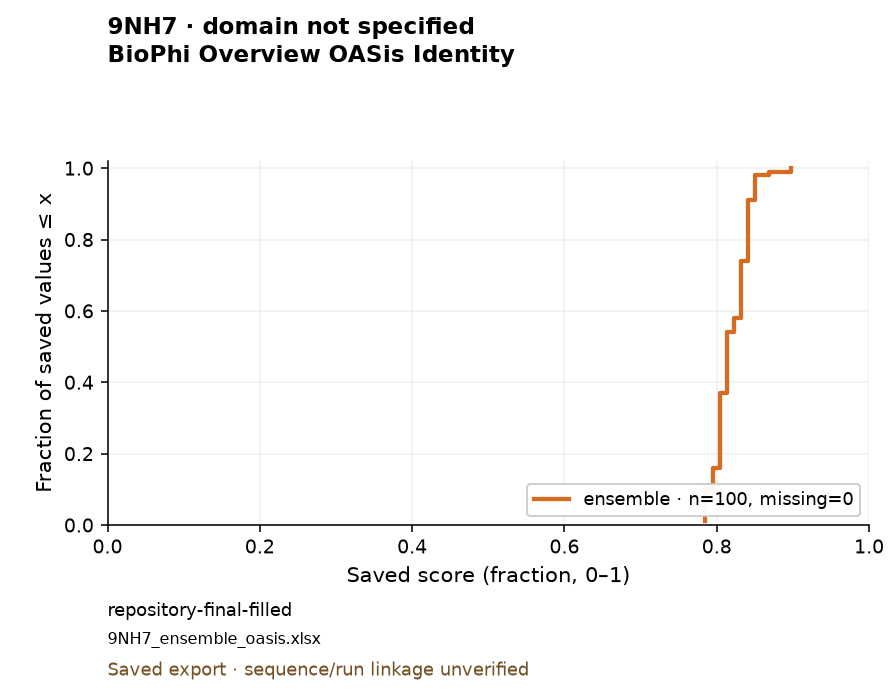

### 9NFU / not-specified-in-export — BioPhi source-selected OASis score

Cohort: **repository-final-filled**. Source: `inputs/sanithu/Oasis_compute/output/oasis_proteinmpnn_summary.csv`. Unpaired saved-value distribution.

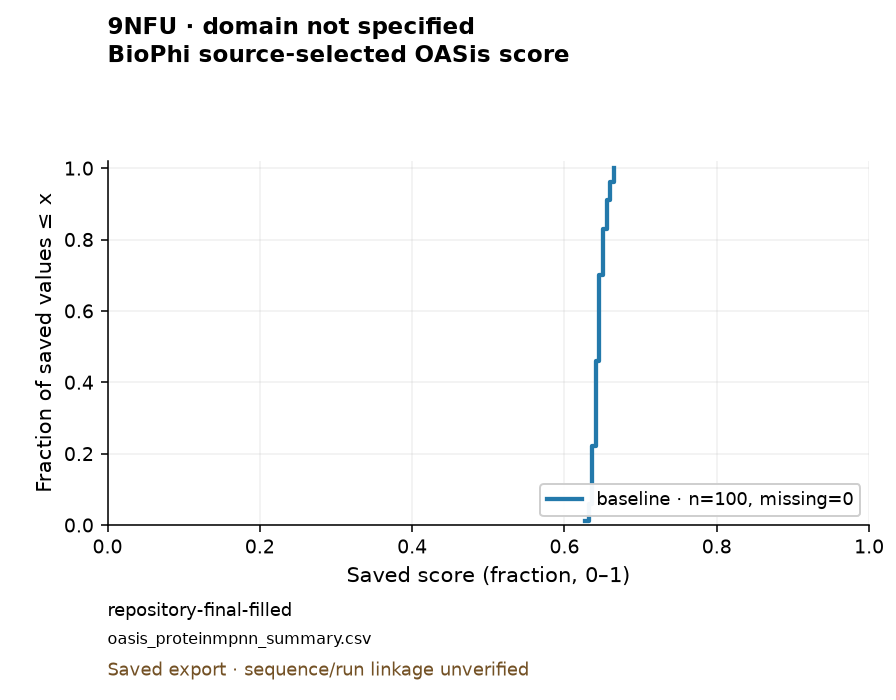

### 9NH7 / not-specified-in-export — BioPhi source-selected OASis score

Cohort: **repository-final-filled**. Source: `inputs/sanithu/Oasis_compute/output/oasis_proteinmpnn_summary.csv`. Unpaired saved-value distribution.

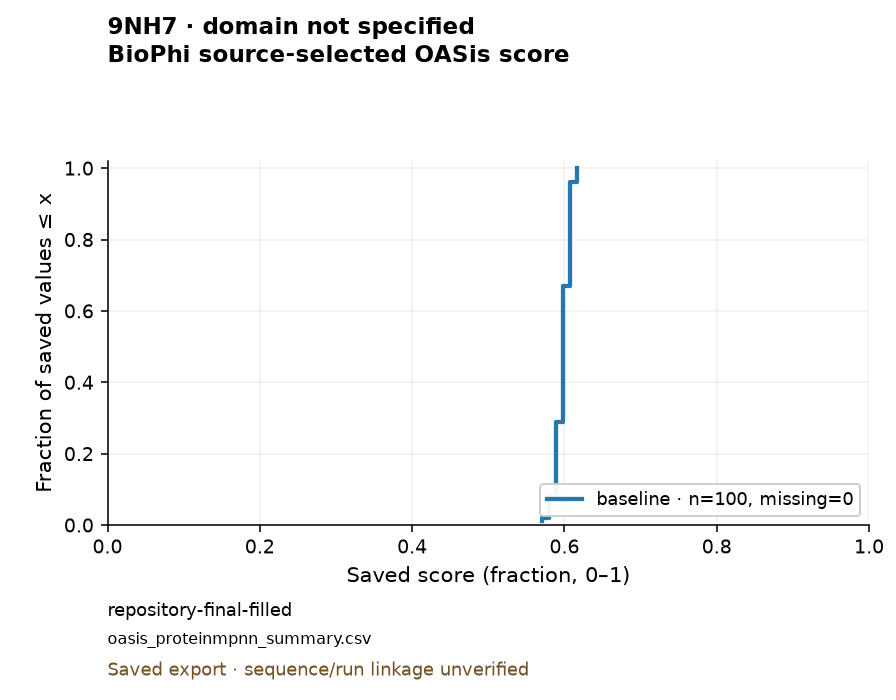

### 9NFU / VH — promb human-oas peptide content (not BioPhi)

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/oasis_scores_promb.csv`. Unpaired saved-value distribution.

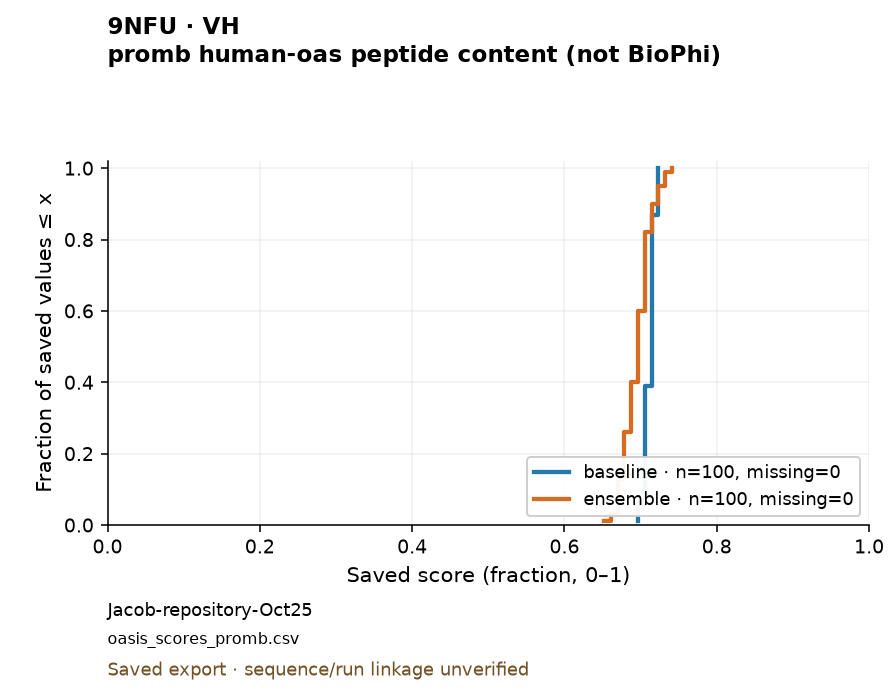

### 9NFU / VL — promb human-oas peptide content (not BioPhi)

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/oasis_scores_promb.csv`. Unpaired saved-value distribution.

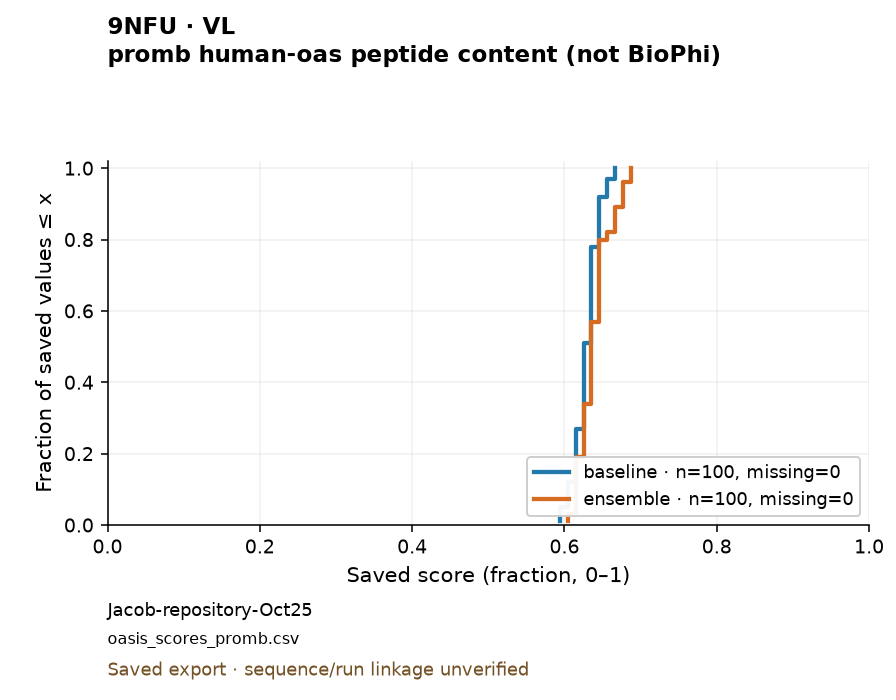

### 9NH7 / VHH — promb human-oas peptide content (not BioPhi)

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/oasis_scores_promb.csv`. Unpaired saved-value distribution.

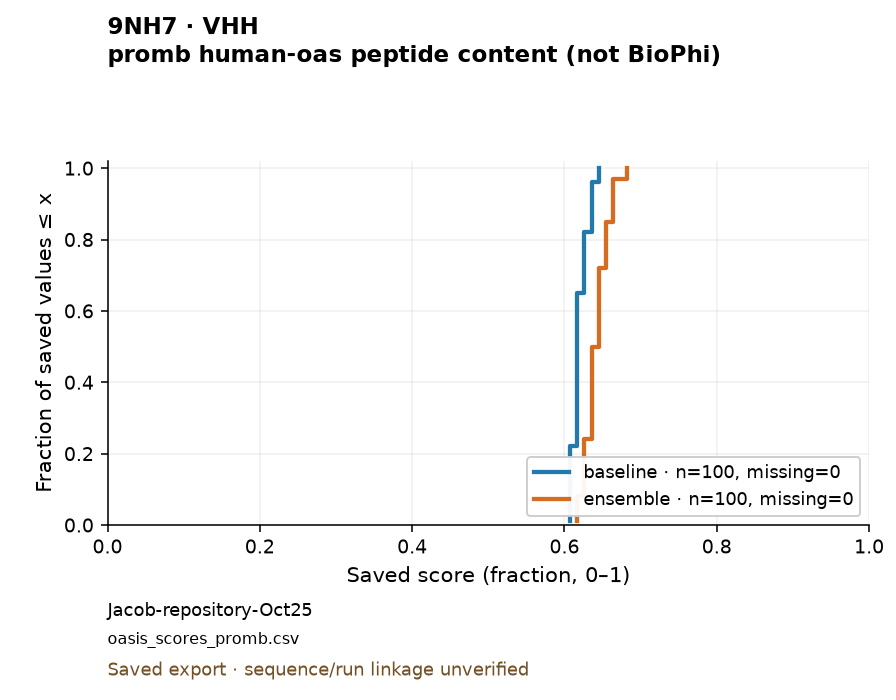

In [7]:
from result_figures import render_sections
render_sections(run["metrics"], "fraction")

## 6. Structure: distributions for every case and domain

Framework RMSD and individual CDR-loop RMSD are separate endpoints in angstroms (Å). Read 9NH7 and 9NFU separately, and compare methods only within the labelled source/domain panel. Smaller values mean smaller reported deviations under that export's alignment, not better binding. Shared horizontal scales within each endpoint keep domain differences visible; no residue mapping or sequence linkage has been validated here.

### 9NFU / VH — Framework RMSD export

Cohort: **repository-final-filled**. Source: `inputs/sanithu/RSMD_RESULTS/cdr_rmsd_framework.csv`. Unpaired saved-value distribution.

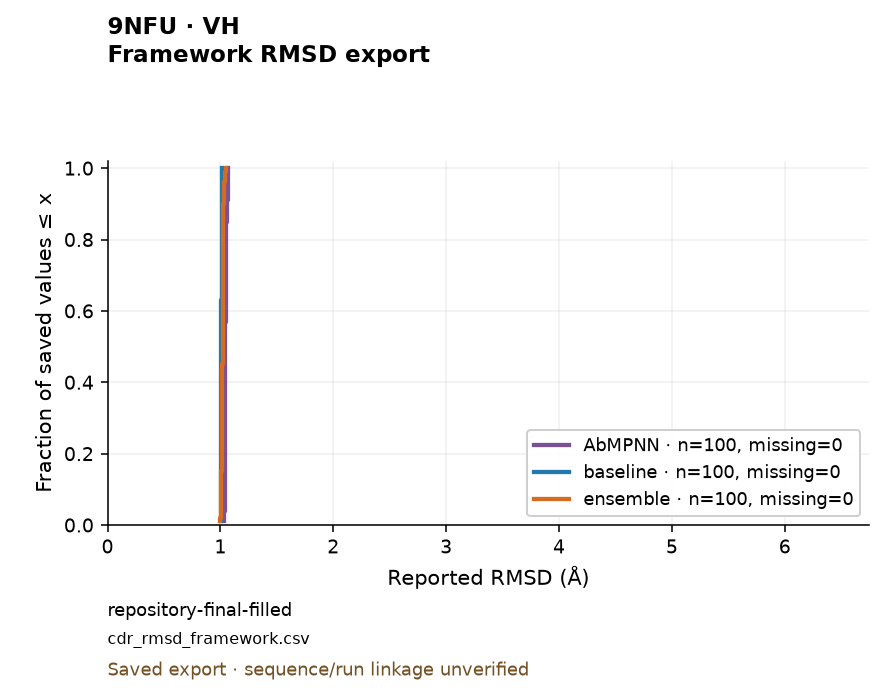

### 9NFU / VL — Framework RMSD export

Cohort: **repository-final-filled**. Source: `inputs/sanithu/RSMD_RESULTS/cdr_rmsd_framework.csv`. Unpaired saved-value distribution.

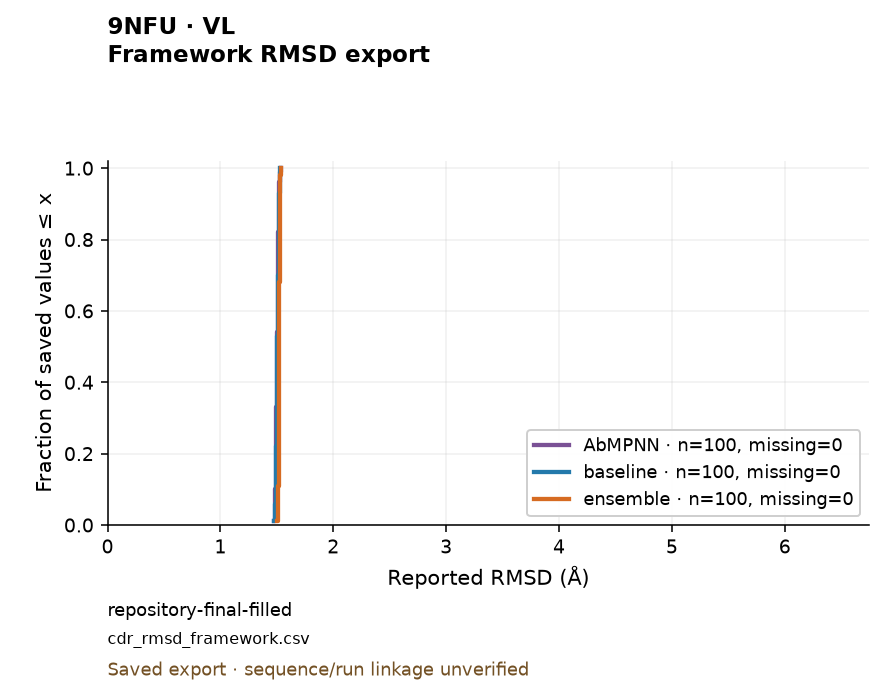

### 9NH7 / VHH — Framework RMSD export

Cohort: **repository-final-filled**. Source: `inputs/sanithu/RSMD_RESULTS/cdr_rmsd_framework.csv`. Unpaired saved-value distribution.

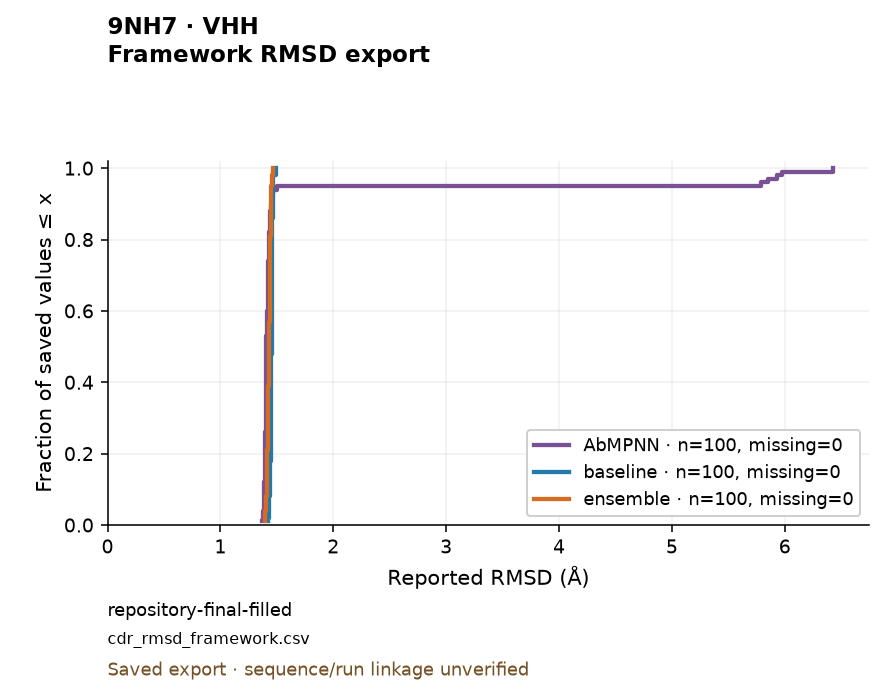

### 9NFU / H1 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

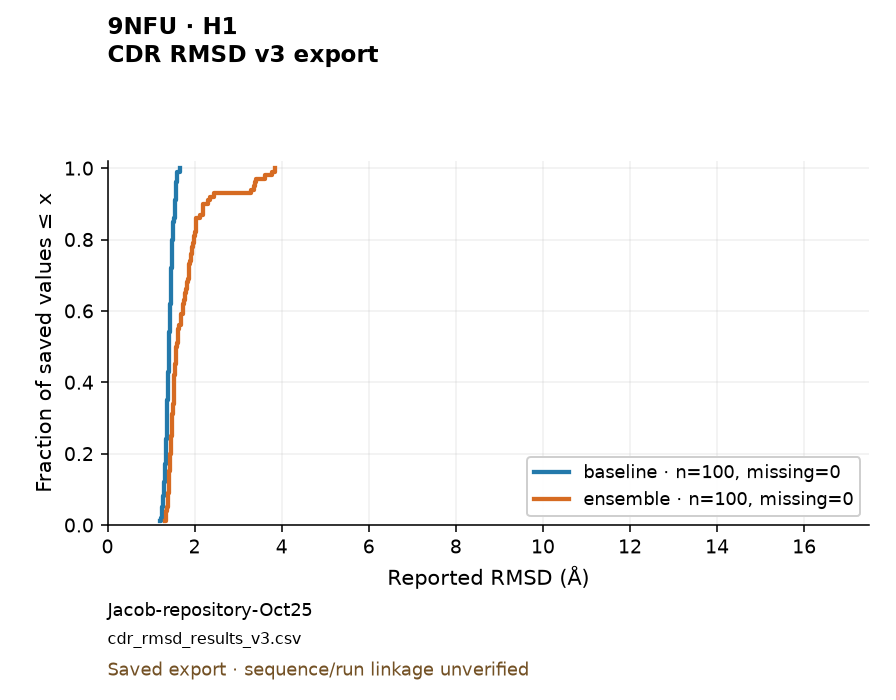

### 9NFU / H2 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

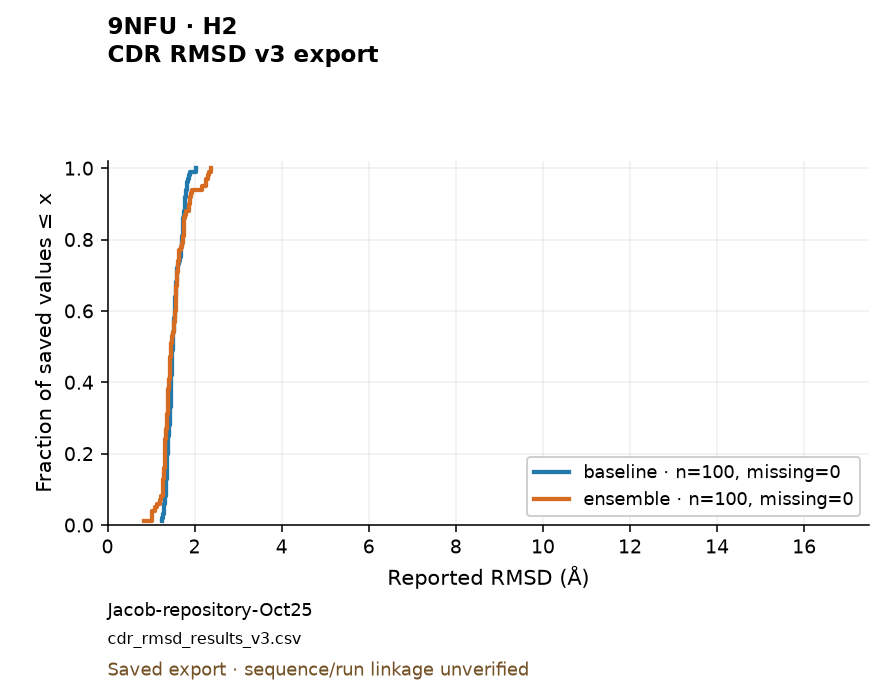

### 9NFU / H3 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

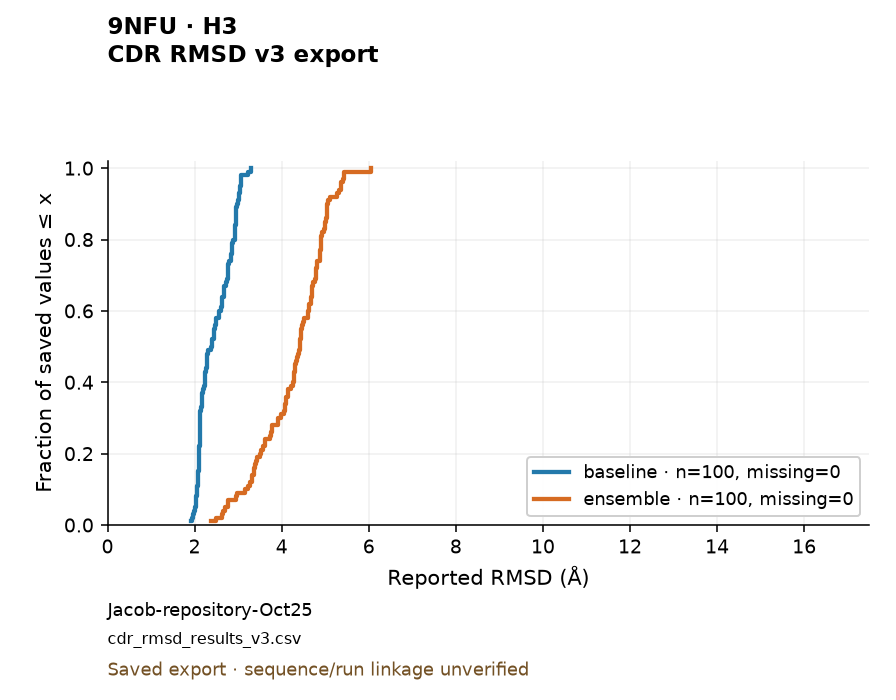

### 9NFU / L1 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

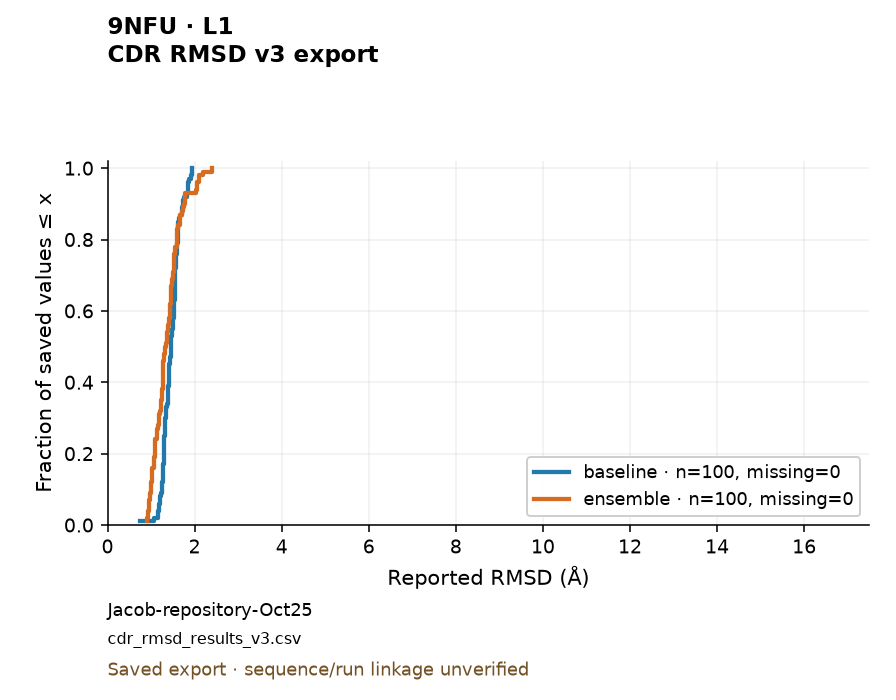

### 9NFU / L2 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

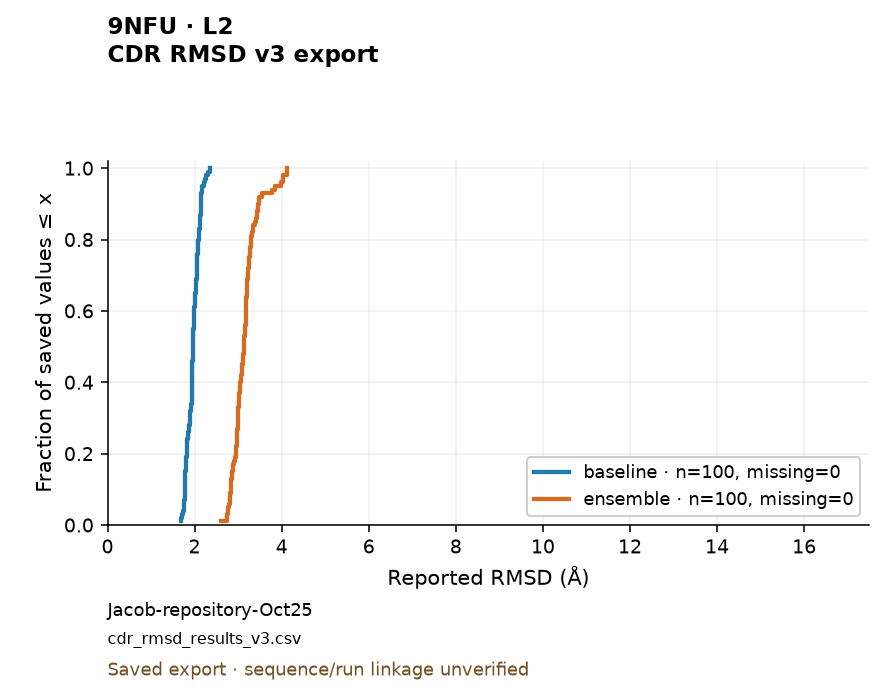

### 9NFU / L3 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

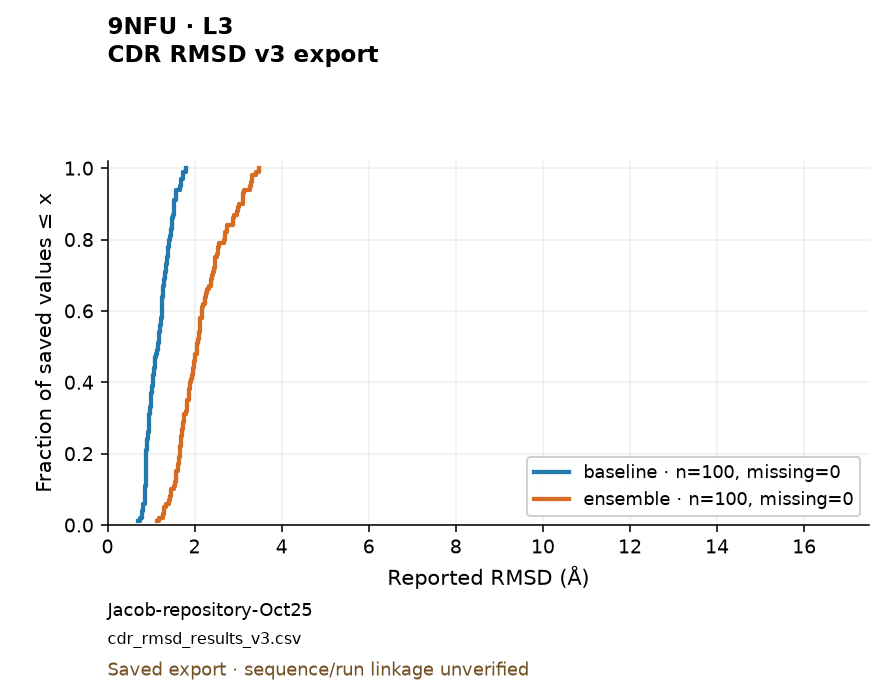

### 9NH7 / H1 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

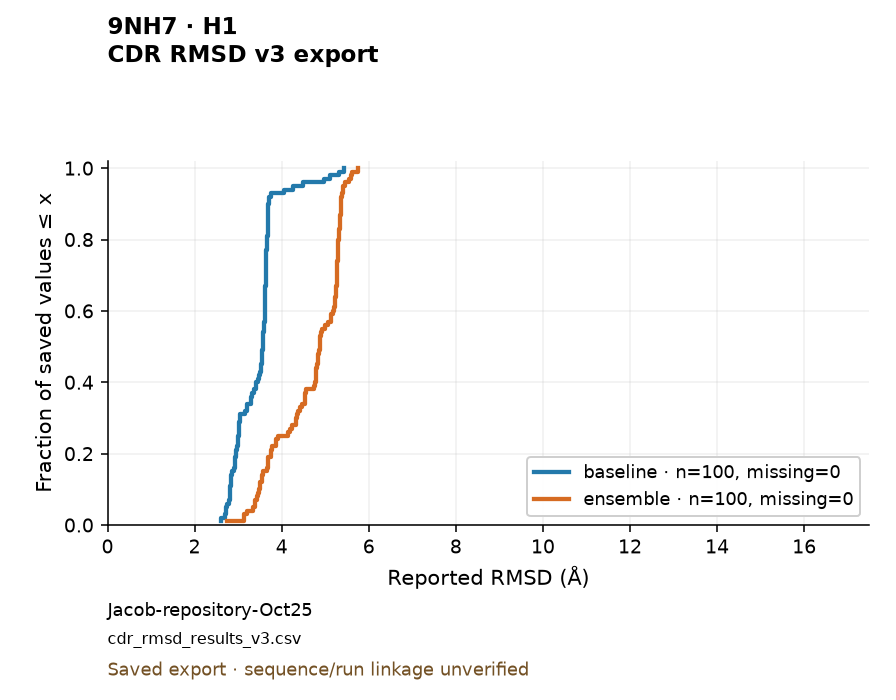

### 9NH7 / H2 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

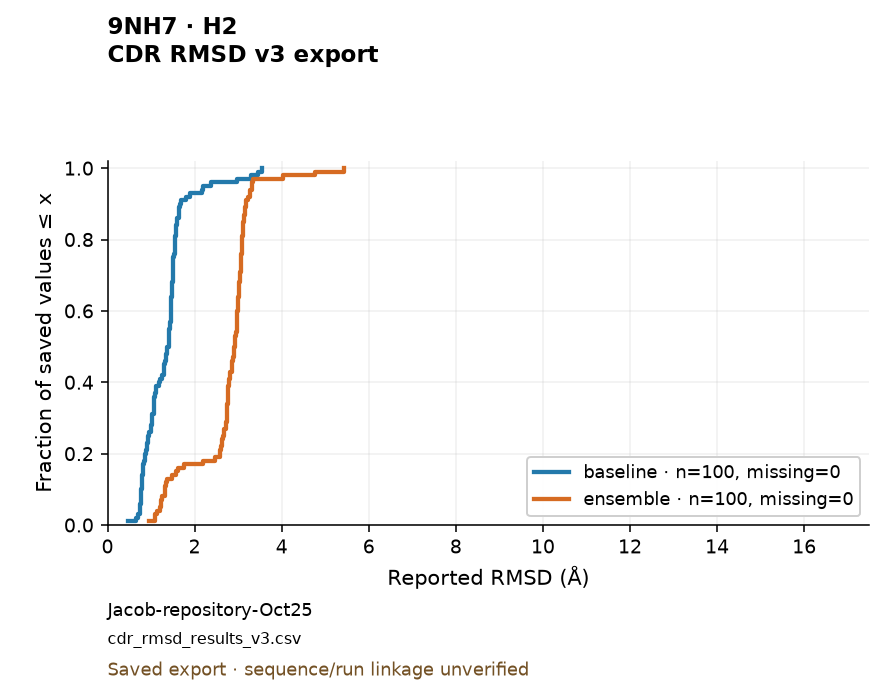

### 9NH7 / H3 — CDR RMSD v3 export

Cohort: **Jacob-repository-Oct25**. Source: `inputs/sanithu/wilcoxon_task_files/3_data/cdr_rmsd_results_v3.csv`. Unpaired saved-value distribution.

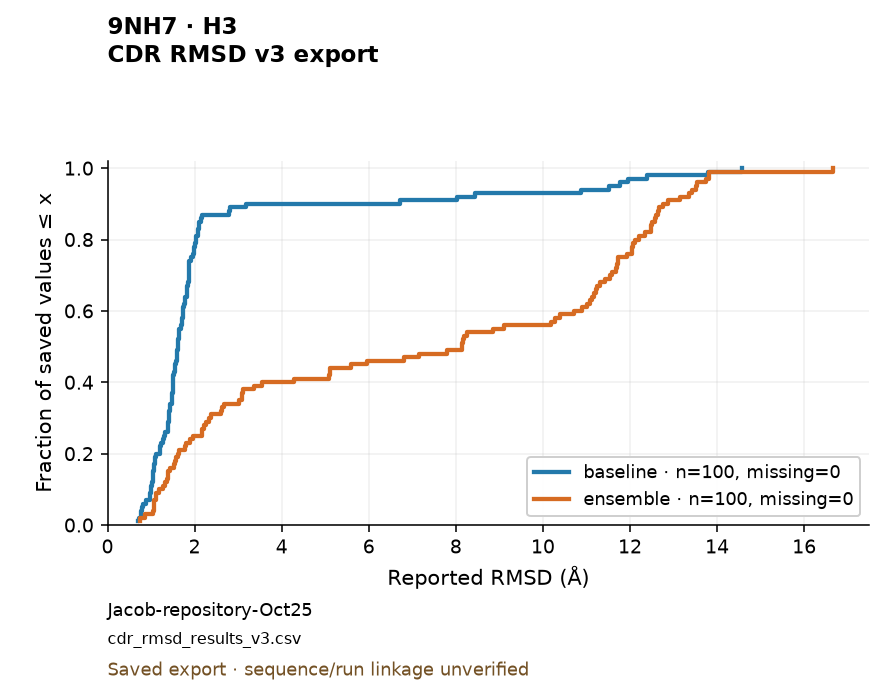

In [8]:
render_sections(run["metrics"], "angstrom")

## 7. What is still missing?

These are concrete reasons not to paste the current summaries into the paper as final results. This list does not mean all computation failed: the saved values above were summarized successfully. It distinguishes that calculation from confirming which inputs produced it.

In [9]:
display(Markdown("\n".join("- " + item for item in run["missing"])))
print("Previous-run comparison:", run["changed_inputs"])

- Latest Jacob Drive / rerun delivery: NOT RECOVERED; included Jacob files are the Oct25 repository snapshot, not a later handoff.
- A run-bound measured-sequence manifest for each OASis and structural export, including source input hashes and settings.
- Corrected baseline identity agreed by the team; current repository and Jacob designs disagree.
- PDB atom/residue mapping and run provenance for structural acceptance; CSVs alone do not validate geometry.
- Team-approved endpoint, cohort and statistical comparison policy; no pairing or hypothesis tests are selected here.
- Original paper-era loop-group ablation inputs remain unverified here; current ablation files are NOT selected in this configuration.
- AbLang trained-head provenance and AbMPNN generation provenance are not established by these saved outputs.

Previous-run comparison: {'status': 'NO_PREVIOUS_BUNDLE_SELECTED', 'changed': [], 'added': [], 'removed': []}


## 8. Save a new review bundle

This creates a dated folder containing tables, figures, exact copies of selected inputs, fingerprints, configuration and the unresolved-items note. It never replaces an earlier folder. If an input changed after loading, export stops and asks you to restart.

The full set was previewed above before export; identical source groups are saved as PNG/SVG files in the bundle.

In [10]:
bundle = update.export_run(run, EXPORT_FOLDER)
print("Saved bundle:", bundle.relative_to(PROJECT_FOLDER))
print("Start with READ_ME_FIRST.md in that folder.")

Saved bundle: exports/update-20261030T045854.519243Z-1b2210ac
Start with READ_ME_FIRST.md in that folder.


## Before a paper update

1. Read `READ_ME_FIRST.md`; resolve the sequence disagreements with the team.
2. Obtain the actual measured-input mapping and structural provenance; do not manufacture a binding by copying hashes from the desired FASTA.
3. Agree which cohort, domain, endpoint and statistical design belong in the manuscript.
4. Only then prepare paper tables from the appropriate validated measurements. Keep this review bundle as the record of what was received.

**No publication or external sharing is performed by this notebook.**